# 04 – RQ2: differences across AI coding agents

**RQ2:** How does the relationship between PR size and review activity differ across AI coding agents (Codex, Copilot, Devin, Cursor, Claude Code)?

**Model.** The RQ1 model with a separate size slope for every agent; human PRs from the same repositories are the reference group:

$$E[y_i] = \exp\Big(\beta_0 \log(1+\text{size}_i) + \sum_a \delta_a\,\text{Agent}_{a,i} + \sum_a \theta_a \log(1+\text{size}_i)\cdot\text{Agent}_{a,i} + \alpha_{\text{repo}} + \gamma_{\text{month}}\Big)$$

* Size elasticity for human PRs is $\beta_0$, for agent $a$ it is $\beta_0 + \theta_a$; $\theta_a$ is the difference to human PRs in the same repositories.
* A Wald test checks whether all agents share the same slope ($H_0: \theta_1 = \dots = \theta_A$).
* Google Jules is excluded (too few repositories). Agents need at least `MIN_AGENT_PRS` PRs.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("ESS_DATA", ROOT / "data"))        # override only for testing
RESULTS = Path(os.environ.get("ESS_RESULTS", ROOT / "results"))
import pandas as pd
import analysis as an
import visualization as viz
viz.setup()
FIG, TAB = RESULTS / "figures", RESULTS / "tables"
TAB.mkdir(parents=True, exist_ok=True)
df = an.load(DATA / "processed/prs.parquet")
MIN_AGENT_PRS = 100   # an agent needs at least this many PRs for its own slope
AGENTS = an.agents_in(df, MIN_AGENT_PRS)
ORDER = ["Human"] + [an.AGENT_LABELS[a] for a in AGENTS]
print("agents analysed:", [an.AGENT_LABELS[a] for a in AGENTS])

agents analysed: ['Codex', 'Copilot', 'Claude Code', 'Cursor', 'Devin']


## 1. How much data per agent, and how concentrated is it?

Agents that come from only a few repositories (e.g. Devin) make their estimate depend on those projects; this table goes into Threats to Validity.

In [2]:
conc = an.concentration(df).loc[ORDER]
conc.to_csv(TAB / "rq2_concentration.csv")
conc.round(3)

,PRs,repositories,share_top5_repos,largest_repo
author_group,,,,
Human,156533,1232,0.024,oxc-project/oxc
Codex,21482,635,0.047,mochilang/mochi
Copilot,34907,664,0.029,github/gh-aw
Claude Code,81259,975,0.012,github/gh-aw
Cursor,7513,253,0.133,ryokun6/ryos
Devin,4818,92,0.208,airbytehq/airbyte


In [3]:
desc = an.describe(df, by="author_group")
desc.to_csv(TAB / "rq2_descriptives.csv")
desc

median                                   \
author_group          Claude Code Codex Copilot Cursor Devin Human   
variable                                                             
files_changed                 4.0   3.0     3.0    3.0   3.0   3.0   
lines_changed               145.0  97.0    88.0   93.0  81.0  88.0   
review_comments_total         0.0   0.0     0.0    0.0   0.0   0.0   
reviewers_total               0.0   0.0     1.0    0.0   1.0   1.0   
reviews_total                 0.0   0.0     1.0    0.0   1.0   1.0   

                             mean                                          \
author_group          Claude Code     Codex   Copilot    Cursor     Devin   
variable                                                                    
files_changed              21.250     9.727    14.854    11.752    16.741   
lines_changed            3086.429  1078.850  2115.318  1255.422  1707.723   
review_comments_total       1.686     0.851     1.692     1.044     1.221   
reviewers_total             0.735     0.454     0.980     0.551     0.782   
reviews_total               1.293     0.693     1.758     0.914     1.321   

                                 share_zero                               \
author_group              Human Claude Code  Codex Copilot Cursor  Devin   
variable                                                                   
files_changed            23.371       0.003  0.003   0.075  0.005  0.004   
lines_changed          3092.324       0.004  0.004   0.076  0.020  0.007   
review_comments_total     2.101       0.705  0.806   0.700  0.761  0.727   
reviewers_total           1.098       0.515  0.678   0.461  0.597  0.452   
reviews_total             1.827       0.515  0.678   0.461  0.597  0.452   

                              
author_group           Human  
variable                      
files_changed          0.005  
lines_changed          0.007  
review_comments_total  0.629  
reviewers_total        0.338  
reviews_total          0.338

## 2. Per-agent size elasticities (main RQ2 result)

In [4]:
rq2, tests = an.rq2_table(df, AGENTS)
rq2.to_csv(TAB / "rq2_elasticities.csv", index=False)
tests.to_csv(TAB / "rq2_equal_slopes_test.csv", index=False)
rq2.round(3)

.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 17588 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 17588 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 9557 observations removed because of separation.
  warnings.warn(


,outcome,size,group,elasticity,se,ci_low,ci_high,p,vs_human,p_vs_human,n_used
0,Reviews,Changed lines (log),Human,0.165,0.004,0.157,0.174,0.000,NaN,NaN,296954
1,Reviews,Changed lines (log),Codex,0.166,0.016,0.135,0.197,0.000,0.001,0.945,296954
2,Reviews,Changed lines (log),Copilot,0.181,0.007,0.167,0.196,0.000,0.016,0.048,296954
3,Reviews,Changed lines (log),Claude Code,0.183,0.008,0.167,0.199,0.000,0.018,0.027,296954
4,Reviews,Changed lines (log),Cursor,0.168,0.028,0.113,0.223,0.000,0.003,0.927,296954
5,Reviews,Changed lines (log),Devin,0.102,0.023,0.056,0.147,0.000,-0.064,0.006,296954
6,Reviews,Changed files (log),Human,0.240,0.008,0.225,0.256,0.000,NaN,NaN,296954
7,Reviews,Changed files (log),Codex,0.268,0.026,0.216,0.320,0.000,0.027,0.303,296954
8,Reviews,Changed files (log),Copilot,0.289,0.013,0.264,0.314,0.000,0.049,0.000,296954
9,Reviews,Changed files (log),Claude Code,0.265,0.014,0.238,0.292,0.000,0.024,0.077,296954


**Do agents differ from each other?** Wald test of equal slopes across agents (p < 0.05 → at least one agent differs):

In [5]:
tests.round(4)

,outcome,size,chi2,df,p
0,Reviews,Changed lines (log),12.1175,4,0.0165
1,Reviews,Changed files (log),12.4881,4,0.0141
2,Inline review comments,Changed lines (log),6.5055,4,0.1644
3,Inline review comments,Changed files (log),11.0186,4,0.0264
4,Distinct reviewers,Changed lines (log),59.5476,4,0.0000
5,Distinct reviewers,Changed files (log),76.6951,4,0.0000


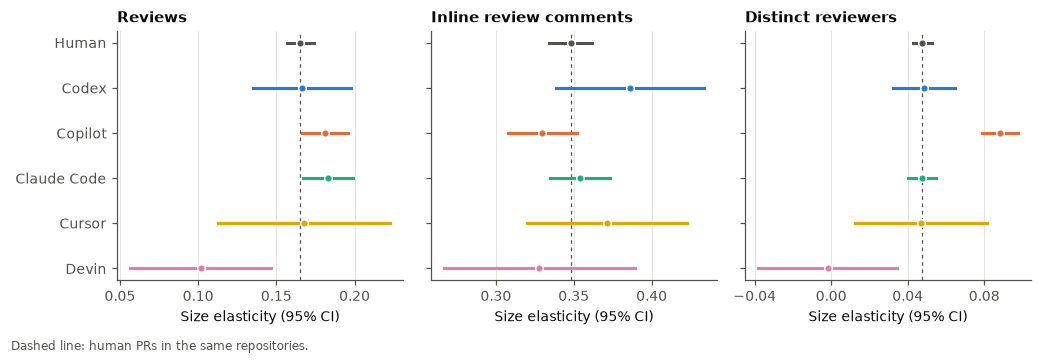

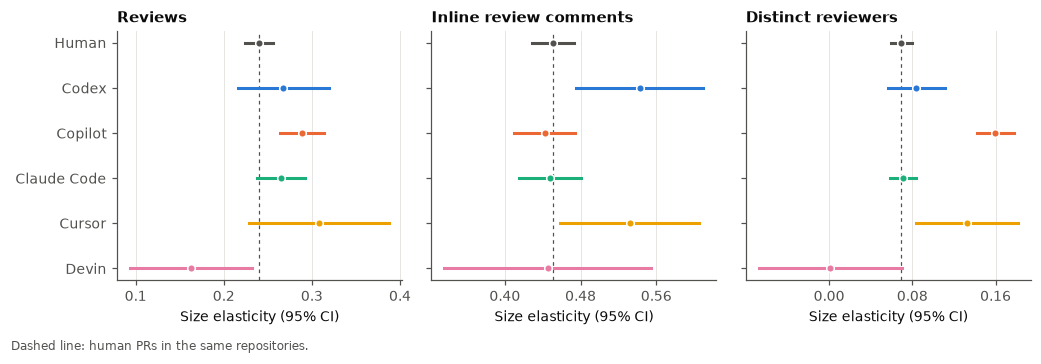

In [6]:
for size, label in an.SIZE_MEASURES.items():
    viz.agent_forest(rq2[rq2["size"] == label], FIG, f"fig_rq2_agents_{size.removeprefix('log_')}")

## 3. How to read the results

* Each dot is the size elasticity for one author group; the dashed line marks human PRs in the same repositories.
* `vs_human` / `p_vs_human`: difference of the agent's slope to human PRs and its p-value.
* A significant equal-slopes test means the size–review relationship is agent-specific; pair it with the concentration table before generalising about an agent.